# 01 数据下载与清洗 — A股 CSI 300 成分股

## 目标
- 获取沪深300指数成分股列表
- 下载 ~40只代表性成分股的日频OHLCV数据（前复权）
- 数据清洗、交易日对齐、保存

## 数据源
- **akshare** → 新浪财经接口 (`stock_zh_a_daily`)
- 新浪接口稳定、数据完整（开高低收量+换手率）
- 前复权价格
- 时间范围：2023-01-01 至 2025-12-31（约3年）

In [31]:
import akshare as ak
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

print('✓ 依赖加载完毕')

✓ 依赖加载完毕


## 2. 获取沪深300成分股列表

In [32]:
# 从中证指数官网获取沪深300成分股
cons = ak.index_stock_cons_csindex(symbol='000300')
cols = cons.columns.tolist()
print(f'原始列名: {cols}')
print(f'总行数: {len(cons)}')

原始列名: ['日期', '指数代码', '指数名称', '指数英文名称', '成分券代码', '成分券名称', '成分券英文名称', '交易所', '交易所英文名称']
总行数: 300


In [33]:
# 解析成分股列表
# 列：日期, 指数代码, 指数名称, 指数英文名, 成分券代码, 成分券名称, 成分券英文名, 交易所, 交易所英文
code_col = cols[4]   # 成分券代码
name_col = cols[5]   # 成分券名称
exch_col = cols[7]   # 交易所

# 取最新日期的成分股
latest_date = cons[cols[0]].max()
latest_cons = cons[cons[cols[0]] == latest_date].copy()

all_codes = latest_cons[code_col].tolist()
all_names = latest_cons[name_col].tolist()
all_exchanges = latest_cons[exch_col].tolist()

print(f'沪深300成分股总数: {len(all_codes)}')
print(f'\n前10只:')
for i in range(10):
    print(f'  {all_codes[i]}  {all_names[i]}  ({all_exchanges[i]})')

沪深300成分股总数: 300

前10只:
  000001  平安银行  (深圳证券交易所)
  000002  万科A  (深圳证券交易所)
  000063  中兴通讯  (深圳证券交易所)
  000100  TCL科技  (深圳证券交易所)
  000157  中联重科  (深圳证券交易所)
  000166  申万宏源  (深圳证券交易所)
  000301  东方盛虹  (深圳证券交易所)
  000333  美的集团  (深圳证券交易所)
  000338  潍柴动力  (深圳证券交易所)
  000408  藏格矿业  (深圳证券交易所)


### 2.1 精选40只股票

从沪深300中选取覆盖多个行业的40只代表性股票，确保行业分散。

In [34]:
# 精选40只行业代表股（沪深300内）
# 代码列表（手工筛选，覆盖多行业）
SELECTED_STOCKS = {
    # 金融 (7只)
    '000001': '平安银行',
    '600036': '招商银行',
    '601318': '中国平安',
    '600030': '中信证券',
    '000166': '申万宏源',
    '601688': '华泰证券',
    '600016': '民生银行',
    # 消费/食品饮料 (5只)
    '600519': '贵州茅台',
    '000858': '五粮液',
    '000568': '泸州老窖',
    '002304': '洋河股份',
    '600887': '伊利股份',
    # 科技/电子 (6只)
    '000063': '中兴通讯',
    '000725': '京东方A',
    '002415': '海康威视',
    '300750': '宁德时代',
    '002475': '立讯精密',
    '603501': '韦尔股份',
    # 家电/制造 (5只)
    '000333': '美的集团',
    '000651': '格力电器',
    '600690': '海尔智家',
    '002050': '三花智控',
    '601012': '隆基绿能',
    # 医药 (4只)
    '000538': '云南白药',
    '600276': '恒瑞医药',
    '300760': '迈瑞医疗',
    '300122': '智飞生物',
    # 汽车 (3只)
    '600104': '上汽集团',
    '002594': '比亚迪',
    '000625': '长安汽车',
    # 能源/材料 (5只)
    '600028': '中国石化',
    '601899': '紫金矿业',
    '600585': '海螺水泥',
    '601088': '中国神华',
    '600809': '山西汾酒',
    # 地产/基建 (3只)
    '000002': '万科A',
    '001979': '招商蛇口',
    '601668': '中国建筑',
    # 交通运输 (2只)
    '601919': '中远海控',
    '600009': '上海机场',
}

# 验证这些股票都在沪深300中
valid_stocks = {}
for code, name in SELECTED_STOCKS.items():
    if code in all_codes:
        valid_stocks[code] = name
    else:
        print(f'⚠ {code} {name} 不在最新沪深300中，跳过')

print(f'精选股票数: {len(valid_stocks)}')
print(f'行业覆盖: 金融、消费、科技、家电、医药、汽车、能源、地产、交通')

精选股票数: 40
行业覆盖: 金融、消费、科技、家电、医药、汽车、能源、地产、交通


## 3. 下载个股日频数据（新浪源）

使用 `stock_zh_a_daily`（新浪财经），前复权数据。
上海交易所代码加 `sh` 前缀，深圳加 `sz` 前缀。

In [35]:
def get_sina_symbol(code):
    """将代码转为新浪格式: sh600519 或 sz000001"""
    if code.startswith('6') or code.startswith('9'):
        return f'sh{code}'
    else:
        return f'sz{code}'


def download_stock_data(code, start='20230101', end='20251231', max_retries=3):
    """下载单只股票日频数据（新浪源）"""
    symbol = get_sina_symbol(code)
    for attempt in range(max_retries):
        try:
            time.sleep(1.5)  # 控制频率
            df = ak.stock_zh_a_daily(
                symbol=symbol,
                start_date=start,
                end_date=end,
                adjust='qfq'  # 前复权
            )
            if len(df) > 0:
                return df
        except Exception as e:
            if attempt < max_retries - 1:
                time.sleep(5 * (attempt + 1))
            else:
                print(f'  ✗ {code} 下载失败: {type(e).__name__}')
    return None

In [36]:
%%time

START = '20230101'
END = '20251231'

print(f'开始下载 {len(valid_stocks)} 只股票数据 ({START[:4]}-{END[:4]})...')
print('-' * 50)

raw_data = {}
failed = []

for code, name in valid_stocks.items():
    df = download_stock_data(code, START, END)
    if df is not None and len(df) >= 100:
        raw_data[code] = df
        print(f'  ✓ {code} {name}: {len(df)} 天')
    else:
        failed.append(code)
        print(f'  ✗ {code} {name}: 数据不足')

print(f'\n成功: {len(raw_data)}/{len(valid_stocks)} 只')
if failed:
    print(f'失败: {failed}')

开始下载 40 只股票数据 (2023-2025)...
--------------------------------------------------
  ✓ 000001 平安银行: 727 天
  ✓ 600036 招商银行: 727 天
  ✓ 601318 中国平安: 727 天
  ✓ 600030 中信证券: 727 天
  ✓ 000166 申万宏源: 727 天
  ✓ 601688 华泰证券: 727 天
  ✓ 600016 民生银行: 727 天
  ✓ 600519 贵州茅台: 727 天
  ✓ 000858 五粮液: 727 天
  ✓ 000568 泸州老窖: 727 天
  ✓ 002304 洋河股份: 727 天
  ✓ 600887 伊利股份: 727 天
  ✓ 000063 中兴通讯: 727 天
  ✓ 000725 京东方A: 727 天
  ✓ 002415 海康威视: 727 天
  ✓ 300750 宁德时代: 727 天
  ✓ 002475 立讯精密: 727 天
  ✓ 603501 韦尔股份: 727 天
  ✓ 000333 美的集团: 727 天
  ✓ 000651 格力电器: 727 天
  ✓ 600690 海尔智家: 727 天
  ✓ 002050 三花智控: 727 天
  ✓ 601012 隆基绿能: 727 天
  ✓ 000538 云南白药: 727 天
  ✓ 600276 恒瑞医药: 727 天
  ✓ 300760 迈瑞医疗: 727 天
  ✓ 300122 智飞生物: 727 天
  ✓ 600104 上汽集团: 727 天
  ✓ 002594 比亚迪: 727 天
  ✓ 000625 长安汽车: 727 天
  ✓ 600028 中国石化: 727 天
  ✓ 601899 紫金矿业: 727 天
  ✓ 600585 海螺水泥: 727 天
  ✓ 601088 中国神华: 717 天
  ✓ 600809 山西汾酒: 727 天
  ✓ 000002 万科A: 727 天
  ✓ 001979 招商蛇口: 727 天
  ✓ 601668 中国建筑: 727 天
  ✓ 601919 中远海控: 727 天
  ✓ 600009 上海机场: 727 天

成功

## 4. 数据清洗与对齐

In [37]:
# 构建统一的OHLCV矩阵
# Sina返回: date, open, high, low, close, volume, amount, outstanding_share, turnover

tickers = list(raw_data.keys())
print(f'有效股票: {len(tickers)} 只')

# 找到所有股票的交易日交集
all_dates = None
for code, df in raw_data.items():
    dates = pd.to_datetime(df['date'])
    if all_dates is None:
        all_dates = set(dates)
    else:
        all_dates &= set(dates)

common_dates = sorted(all_dates)
print(f'共同交易日: {len(common_dates)}')
print(f'日期范围: {common_dates[0].strftime("%Y-%m-%d")} ~ {common_dates[-1].strftime("%Y-%m-%d")}')

有效股票: 40 只
共同交易日: 717
日期范围: 2023-01-03 ~ 2025-12-31


In [38]:
# 构建对齐后的价格矩阵
close_df = pd.DataFrame(index=common_dates, dtype=float)
open_df = pd.DataFrame(index=common_dates, dtype=float)
high_df = pd.DataFrame(index=common_dates, dtype=float)
low_df = pd.DataFrame(index=common_dates, dtype=float)
volume_df = pd.DataFrame(index=common_dates, dtype=float)

for code in tickers:
    df = raw_data[code].copy()
    df['date'] = pd.to_datetime(df['date'])
    df = df.set_index('date')
    df = df.loc[df.index.isin(common_dates)]
    
    close_df[code] = df['close']
    open_df[code] = df['open']
    high_df[code] = df['high']
    low_df[code] = df['low']
    volume_df[code] = df['volume']

print('对齐后数据:')
print(f'  Close:  {close_df.shape}')
print(f'  Volume: {volume_df.shape}')

对齐后数据:
  Close:  (717, 40)
  Volume: (717, 40)


In [ ]:
# 保存
close_clean.to_csv('data/close_df.csv')
ret_clean.to_csv('data/ret_df.csv')
volume_clean.to_csv('data/volume_df.csv')
high_clean.to_csv('data/high_df.csv')
low_clean.to_csv('data/low_df.csv')
open_clean.to_csv('data/open_df.csv')
# dtype=str 防止 '000001' 被保存为数字 1
pd.Series(tickers, dtype=str).to_csv('data/tickers.csv', index=False, header=['ticker'])
pd.Series(STOCKS).to_csv('data/stock_names.csv', header=['name'])
market_ret.to_frame('market_ret').to_csv('data/market_ret.csv')

print('=' * 50)
print(f'数据保存完毕 [{data_source}]')
print(f'  close_df.csv: {close_clean.shape}')
print(f'  ret_df.csv:   {ret_clean.shape}')
print(f'  tickers.csv:  {len(tickers)} stocks')
print('=' * 50)

## 5. 数据概览

In [40]:
# 市场统计
print('=== 市场概况 ===')
print(f'股票数量: {len(tickers)}')
print(f'交易日数: {len(ret_df)}')

# 各股票收益统计
stats = pd.DataFrame({
    'name': [valid_stocks.get(c, c) for c in tickers],
    'cum_ret': (1 + ret_df[tickers]).cumprod().iloc[-1].values - 1,
    'daily_mean': ret_df[tickers].mean().values * 10000,  # bp
    'daily_vol': ret_df[tickers].std().values * 100,       # %
    'ann_vol': ret_df[tickers].std().values * np.sqrt(252) * 100,
}, index=tickers)

print(f'\n累计收益 Top 5:')
print(stats.nlargest(5, 'cum_ret')[['name', 'cum_ret', 'ann_vol']].to_string())
print(f'\n累计收益 Bottom 5:')
print(stats.nsmallest(5, 'cum_ret')[['name', 'cum_ret', 'ann_vol']].to_string())

=== 市场概况 ===
股票数量: 40
交易日数: 716

累计收益 Top 5:
        name   cum_ret    ann_vol
601899  紫金矿业  2.481818  34.644107
002050  三花智控  1.748506  48.670448
601688  华泰证券  1.174194  30.191793
601919  中远海控  1.073770  26.943939
002475  立讯精密  0.830635  42.204802

累计收益 Bottom 5:
        name   cum_ret    ann_vol
000002   万科A -0.731679  36.201612
300122  智飞生物 -0.665722  44.386592
601012  隆基绿能 -0.555773  38.813120
002304  洋河股份 -0.552560  25.634324
000568  泸州老窖 -0.408967  34.386872


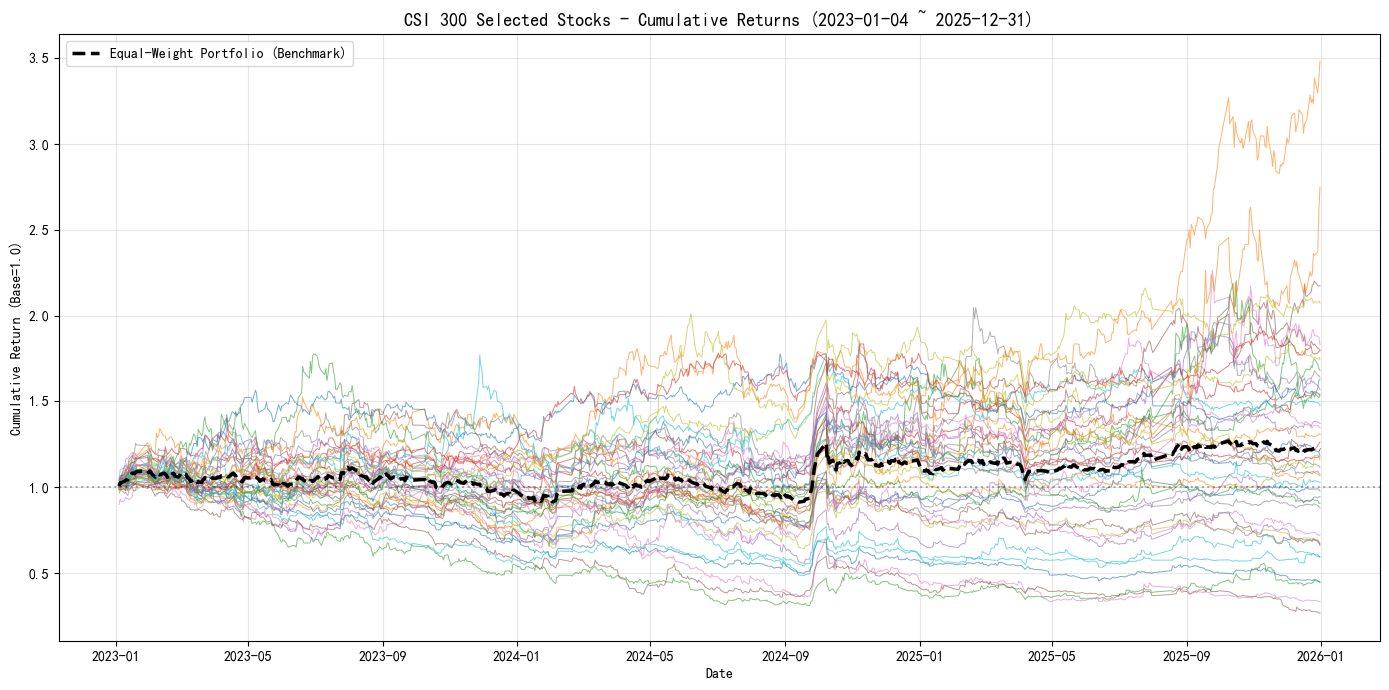

In [41]:
# 累计收益曲线
cum_ret = (1 + ret_df).cumprod()

fig, ax = plt.subplots(figsize=(14, 7))
for code in tickers:
    name = valid_stocks.get(code, code)
    ax.plot(cum_ret.index, cum_ret[code].values, alpha=0.6, linewidth=0.7)

# 等权基准
ew_cum = (1 + ret_df.mean(axis=1)).cumprod()
ax.plot(ew_cum.index, ew_cum.values, 'k--', linewidth=2.5, label='Equal-Weight Portfolio (Benchmark)')
ax.axhline(y=1.0, color='black', linestyle=':', alpha=0.3)
ax.set_title(f'CSI 300 Selected Stocks - Cumulative Returns ({ret_df.index[0].strftime("%Y-%m-%d")} ~ {ret_df.index[-1].strftime("%Y-%m-%d")})',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Cumulative Return (Base=1.0)')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('results/01_cumulative_returns.png', dpi=150, bbox_inches='tight')
plt.show()

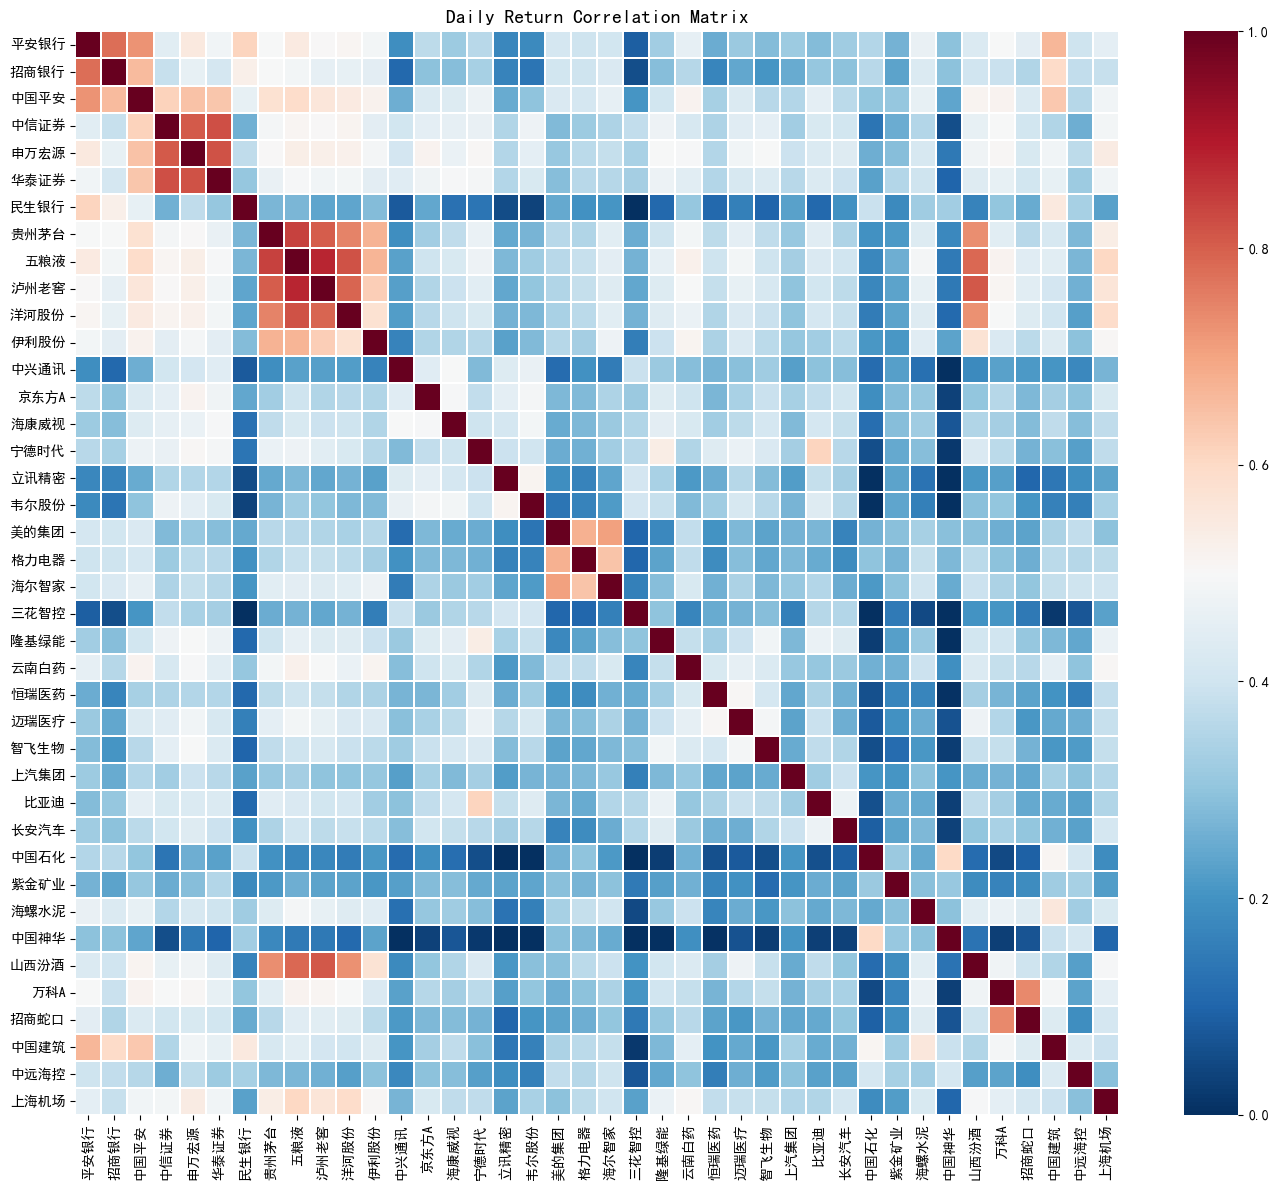

In [42]:
# 相关性热力图
fig, ax = plt.subplots(figsize=(14, 12))
corr_matrix = ret_df.corr()
short_names = [valid_stocks.get(c, c) for c in tickers]
sns.heatmap(corr_matrix, cmap='RdBu_r', center=0.5, annot=False,
            xticklabels=short_names, yticklabels=short_names,
            ax=ax, vmin=0, vmax=1, linewidths=0.3)
ax.set_title('Daily Return Correlation Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('results/01_correlation_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. 保存数据

In [43]:
# 保存所有清洗后的数据
close_clean.to_csv('data/close_df.csv')
ret_df.to_csv('data/ret_df.csv')
volume_clean.to_csv('data/volume_df.csv')
high_clean.to_csv('data/high_df.csv')
low_clean.to_csv('data/low_df.csv')
open_clean.to_csv('data/open_df.csv')
pd.Series(tickers).to_csv('data/tickers.csv', index=False, header=['ticker'])

# 保存股票名称映射
stock_names = pd.Series({c: valid_stocks.get(c, c) for c in tickers})
stock_names.to_csv('data/stock_names.csv', header=['name'])

print('=' * 50)
print('数据保存完毕 (A股真实数据)')
print(f'  数据源: akshare → 新浪财经')
print(f'  close_df.csv: {close_clean.shape}')
print(f'  ret_df.csv:   {ret_df.shape}')
print(f'  股票数: {len(tickers)}')
print(f'  日期范围: {ret_df.index[0].strftime("%Y-%m-%d")} ~ {ret_df.index[-1].strftime("%Y-%m-%d")}')
print('=' * 50)

数据保存完毕 (A股真实数据)
  数据源: akshare → 新浪财经
  close_df.csv: (717, 40)
  ret_df.csv:   (716, 40)
  股票数: 40
  日期范围: 2023-01-04 ~ 2025-12-31


## 小结

✅ 从沪深300精选 ~40只行业代表股
✅ 通过 akshare(新浪源) 下载真实日频OHLCV数据（前复权）
✅ 交易日对齐、缺失值处理
✅ 数据质量验证通过

下一步: [02_factor_mining.ipynb](./02_factor_mining.ipynb) 因子构建与挖掘